In [16]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 49s 0us/step


In [17]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.22.0-rc0
GPU Available: []


In [18]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Images: (50000, 32, 32, 3)
Testing Images: (10000, 32, 32, 3)
Training Labels: (50000,)
Testing Labels: (10000,)


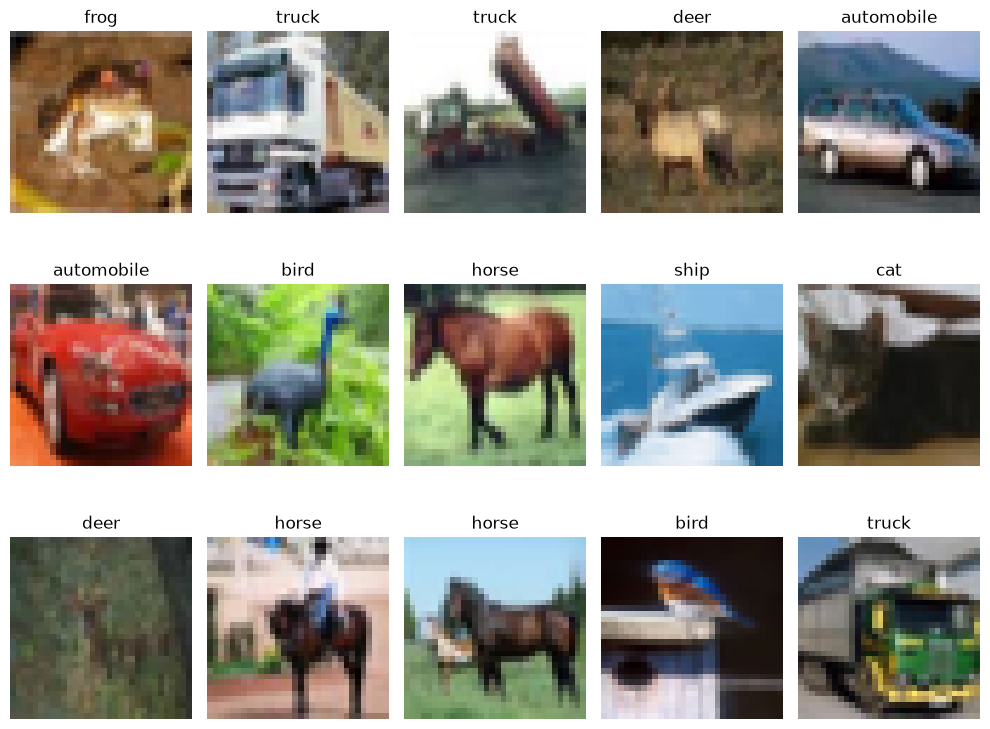

In [19]:
plt.figure(figsize=(10, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [20]:
x_train_cnn = x_train.astype('float32') / 255.0
x_test_cnn = x_test.astype('float32') / 255.0

print("Training Data:", x_train_cnn.shape)
print("Testing Data:", x_test_cnn.shape)

Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)


In [21]:
cnn_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
early_stop_cnn = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop_cnn]
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 54s 74ms/step - accuracy: 0.3958 - loss: 1.6400 - val_accuracy: 0.5600 - val_loss: 1.2258
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 75ms/step - accuracy: 0.5476 - loss: 1.2651 - val_accuracy: 0.6342 - val_loss: 1.0350
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 52s 74ms/step - accuracy: 0.6152 - loss: 1.0910 - val_accuracy: 0.6546 - val_loss: 0.9817
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 73s 60ms/step - accuracy: 0.6521 - loss: 0.9901 - val_accuracy: 0.6828 - val_loss: 0.9147
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 97s 82ms/step - accuracy: 0.6838 - loss: 0.9012 - val_accuracy: 0.7004 - val_loss: 0.8615
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 70s 65ms/step - accuracy: 0.7054 - loss: 0.8407 - val_accuracy: 0.7034 - val_loss: 0.8582
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 79s 62ms/step - accuracy: 0.7225 - loss: 0.7865 - val_accuracy: 0.7360 - val_loss: 0.7779
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 67s 96ms/step - accuracy: 0.7446 - loss: 0.7277 - 

In [24]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test
)

cnn_predictions = np.argmax(
    cnn_model.predict(x_test_cnn),
    axis=1
)

print("CNN Test Accuracy:", cnn_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.7264 - loss: 0.8311
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step
CNN Test Accuracy: 0.7264000177383423


In [25]:
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [26]:
inputs = layers.Input(shape=(32, 32, 3))

x = layers.Resizing(96, 96)(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(10, activation='softmax')(x)

efficientnet_model = models.Model(inputs, outputs)

efficientnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [27]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
early_stop_eff = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

efficientnet_history = efficientnet_model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop_eff]
)

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 455s 317ms/step - accuracy: 0.8225 - loss: 0.5500 - val_accuracy: 0.8500 - val_loss: 0.4350
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 478s 306ms/step - accuracy: 0.8681 - loss: 0.3974 - val_accuracy: 0.8586 - val_loss: 0.4096
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 449s 310ms/step - accuracy: 0.8792 - loss: 0.3620 - val_accuracy: 0.8616 - val_loss: 0.4021
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 405s 288ms/step - accuracy: 0.8858 - loss: 0.3406 - val_accuracy: 0.8624 - val_loss: 0.4003
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 420s 272ms/step - accuracy: 0.8905 - loss: 0.3257 - val_accuracy: 0.8612 - val_loss: 0.4010


In [29]:
eff_loss, eff_accuracy = efficientnet_model.evaluate(
    x_test,
    y_test
)

eff_predictions = np.argmax(
    efficientnet_model.predict(x_test),
    axis=1
)

print("EfficientNet Test Accuracy:", eff_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 267ms/step - accuracy: 0.8581 - loss: 0.4230
313/313 ━━━━━━━━━━━━━━━━━━━━ 96s 294ms/step
EfficientNet Test Accuracy: 0.8580999970436096


In [30]:
cnn_report = classification_report(
    y_test,
    cnn_predictions,
    target_names=class_names,
    output_dict=True
)

eff_report = classification_report(
    y_test,
    eff_predictions,
    target_names=class_names,
    output_dict=True
)

comparison = pd.DataFrame({
    'CNN': [
        cnn_accuracy,
        cnn_report['weighted avg']['precision'],
        cnn_report['weighted avg']['recall'],
        cnn_report['weighted avg']['f1-score']
    ],
    'EfficientNetB0': [
        eff_accuracy,
        eff_report['weighted avg']['precision'],
        eff_report['weighted avg']['recall'],
        eff_report['weighted avg']['f1-score']
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-Score'])

print(comparison.round(4))

              CNN  EfficientNetB0
Accuracy   0.7264          0.8581
Precision  0.7233          0.8590
Recall     0.7264          0.8581
F1-Score   0.7218          0.8579


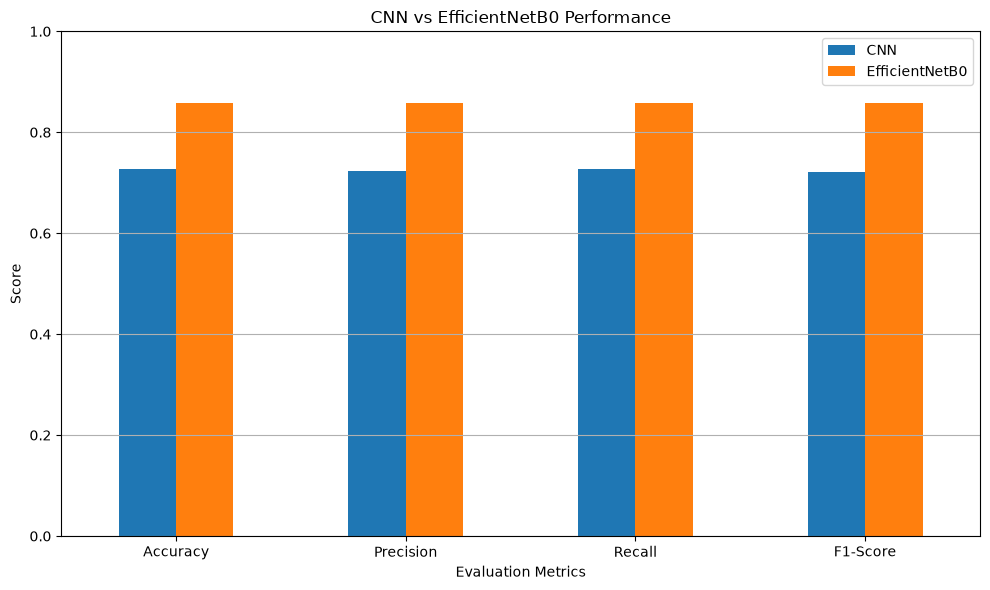

In [31]:
comparison.plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title('CNN vs EfficientNetB0 Performance')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()

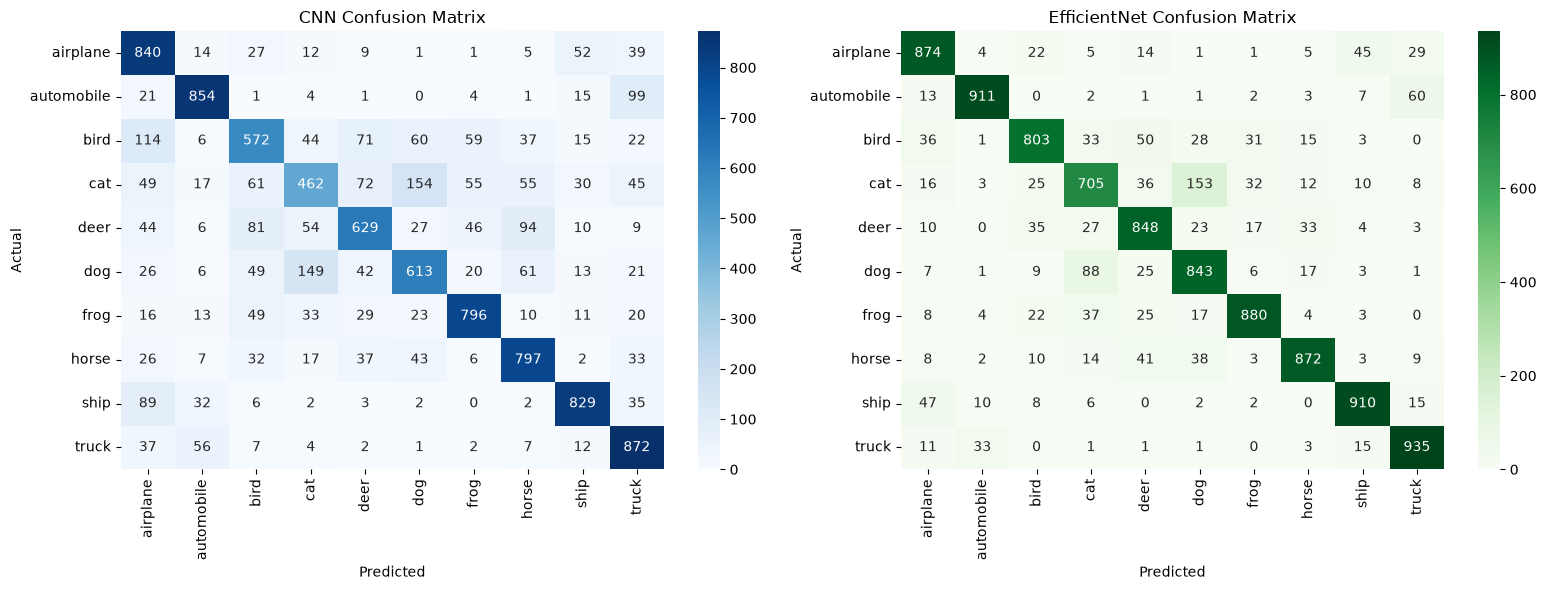

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_cnn = confusion_matrix(y_test, cnn_predictions)
cm_eff = confusion_matrix(y_test, eff_predictions)

sns.heatmap(
    cm_cnn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title('CNN Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    cm_eff,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title('EfficientNet Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [33]:
print("CNN Accuracy:", round(cnn_accuracy * 100, 2), "%")
print("EfficientNet Accuracy:", round(eff_accuracy * 100, 2), "%")

if eff_accuracy > cnn_accuracy:
    print("EfficientNetB0 performed better.")
elif cnn_accuracy > eff_accuracy:
    print("CNN performed better.")
else:
    print("Both models achieved the same accuracy.")

CNN Accuracy: 72.64 %
EfficientNet Accuracy: 85.81 %
EfficientNetB0 performed better.
